# Student Performance Data Analysis

This mini project explore the Students Performance dataset, cleans inconsistent values, engineers useful features, and performs basic Data anipulation & Exploratory Data Analysis(EDA)

## 1. Load and Inspect the dataset

Load the students performance data and take an initial look at it's rows, columns, data types and identify the missing values

In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib as mpl
mpl.rcParams['figure.figsize'] = [20, 10]

df1 = pd.read_csv("StudentsPerformance.csv")
df1.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
df1.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [4]:
df1.shape

(1000, 8)

In [5]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [6]:
df1.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [7]:
df1.groupby('test preparation course')[['math score', 'reading score', 'writing score']].mean()

,math score,reading score,writing score
test preparation course,,,
completed,69.695531,73.893855,74.418994
none,64.077882,66.534268,64.504673


In [8]:
df1.groupby('lunch')[['math score', 'reading score', 'writing score']].mean()

,math score,reading score,writing score
lunch,,,
free/reduced,58.921127,64.653521,63.022535
standard,70.034109,71.654264,70.823256


## 2. Feature Engineering

Displaying the calculated mean, median and the standard deviation for the students' performance 

In [9]:
df1['total score'] = df1['math score'] + df1['reading score'] + df1['writing score']
df1['average score'] = df1['total score']/3
df1['median'] = df1['average score'].median()
df1['std_dev'] = df1['average score'].std()
df1['status'] = np.where(df1['average score'] >= 50, 'Pass', 'Fail')

In [10]:
df2 = df1.copy()
df2.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total score,average score,median,std_dev,status
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667,68.333333,14.257326,Pass
1,female,group C,some college,standard,completed,69,90,88,247,82.333333,68.333333,14.257326,Pass
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667,68.333333,14.257326,Pass
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333,68.333333,14.257326,Fail
4,male,group C,some college,standard,none,76,78,75,229,76.333333,68.333333,14.257326,Pass


In [11]:
df2.drop(['median', 'std_dev'], axis = 'columns', inplace = True)
df2.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total score,average score,status
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667,Pass
1,female,group C,some college,standard,completed,69,90,88,247,82.333333,Pass
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667,Pass
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333,Fail
4,male,group C,some college,standard,none,76,78,75,229,76.333333,Pass


## 3. Categorical Breakdown
To analyze and compare Students score across genders, lunch, race/ethnicity and other variable categories

In [12]:
df2.groupby('gender')[['math score', 'reading score', 'writing score', 'average score']].mean()

,math score,reading score,writing score,average score
gender,,,,
female,63.633205,72.608108,72.467181,69.569498
male,68.728216,65.473029,63.311203,65.837483


In [13]:
df2.groupby('parental level of education')['average score'].mean().sort_values(ascending=False)

parental level of education
master's degree       73.598870
bachelor's degree     71.923729
associate's degree    69.569069
some college          68.476401
some high school      65.108007
high school           63.096939
Name: average score, dtype: float64

In [14]:
df2.groupby('race/ethnicity')['average score'].mean()

race/ethnicity
group A    62.992509
group B    65.468421
group C    67.131661
group D    69.179389
group E    72.752381
Name: average score, dtype: float64

## 4. Data Visualisation
Visualizing the distribution of student scores across subjects and comparing score spreads across different categories

<Axes: xlabel='average score', ylabel='Count'>

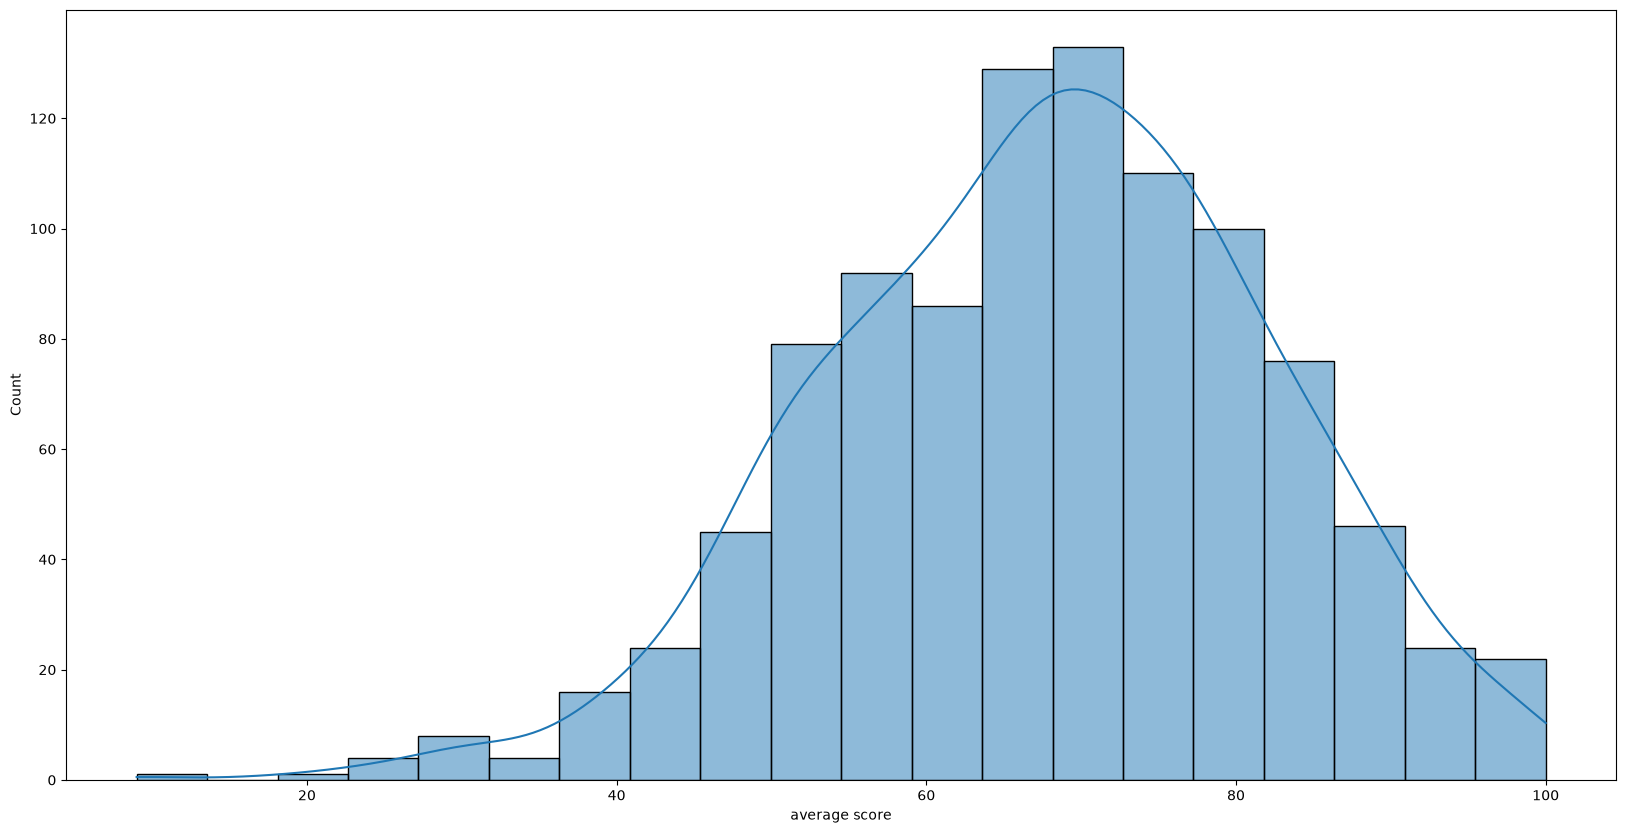

In [15]:
import seaborn as sns
sns.histplot(data = df2, x = 'average score', kde = True, bins = 20)

<Axes: xlabel='average score', ylabel='Count'>

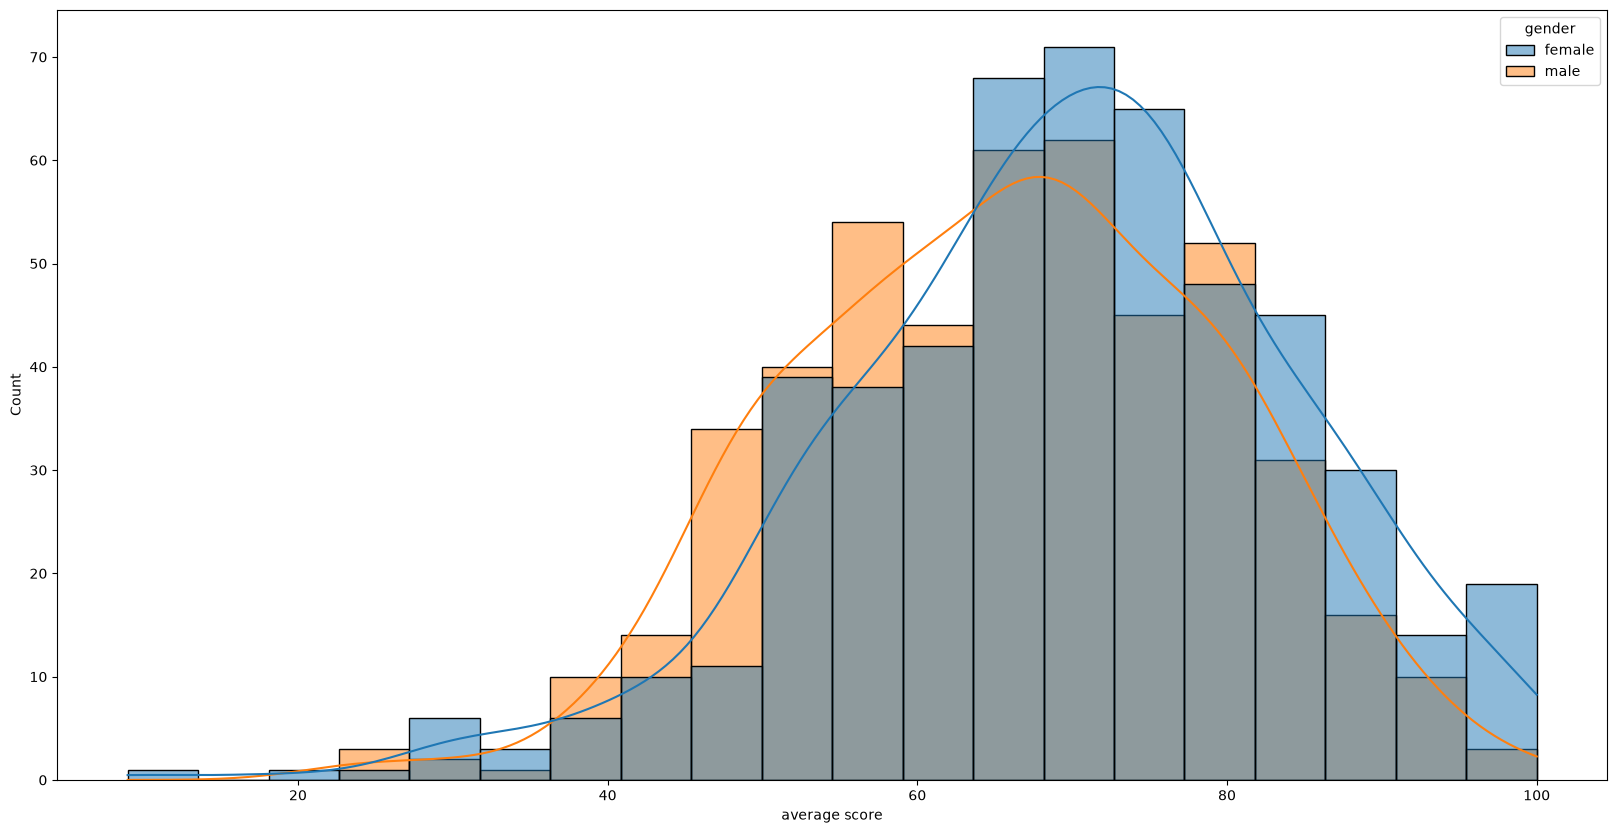

In [16]:
sns.histplot(data = df2, x = 'average score', hue = 'gender', kde = True, bins = 20)

<Axes: xlabel='average score', ylabel='Count'>

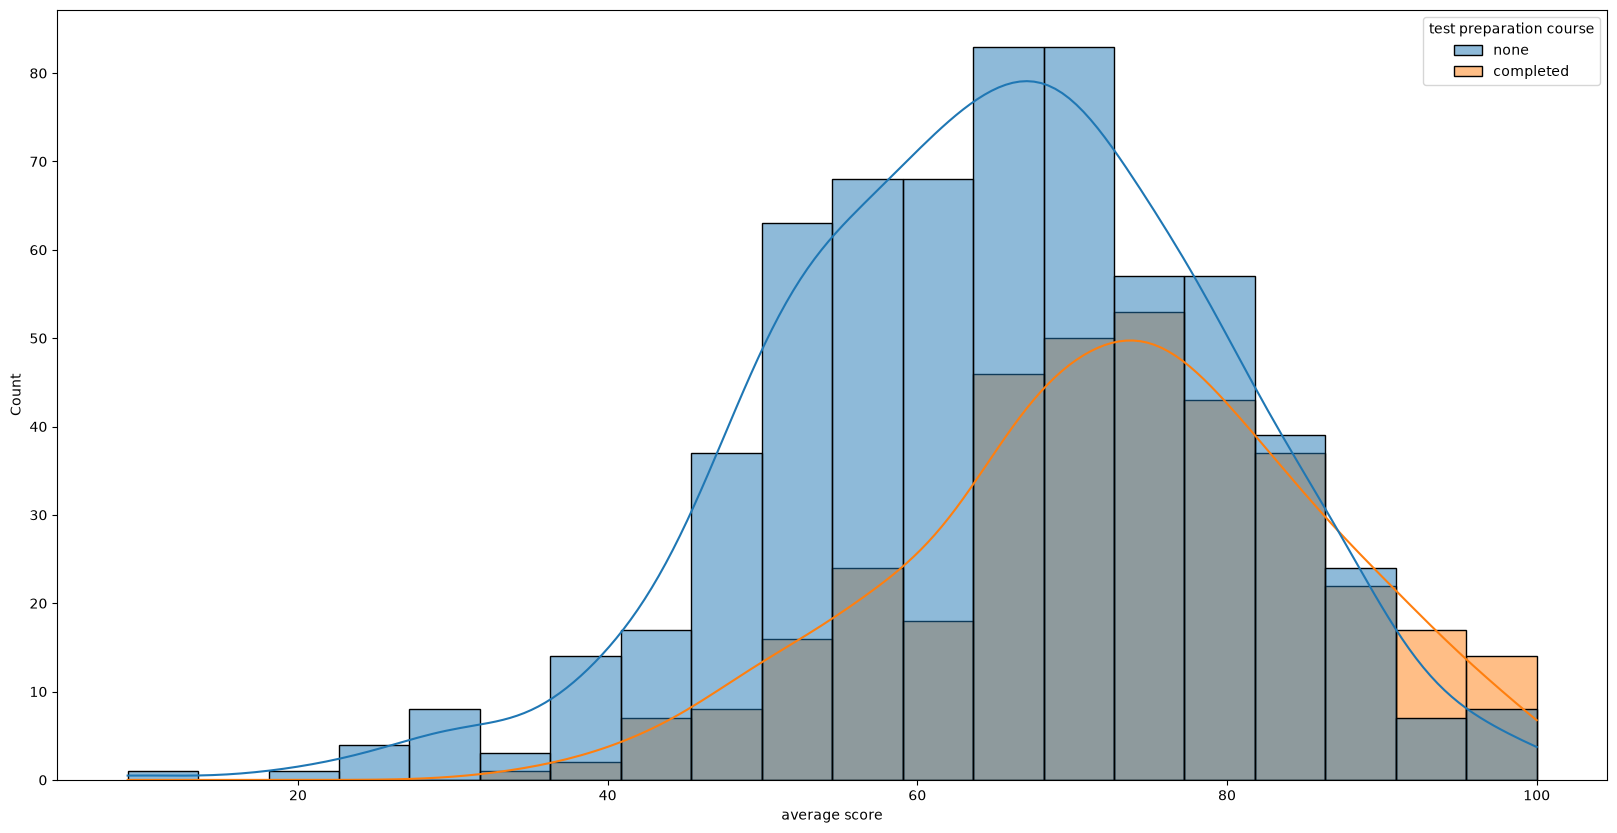

In [17]:
sns.histplot(data = df2, x = 'average score', hue = 'test preparation course', kde = True, bins = 20)

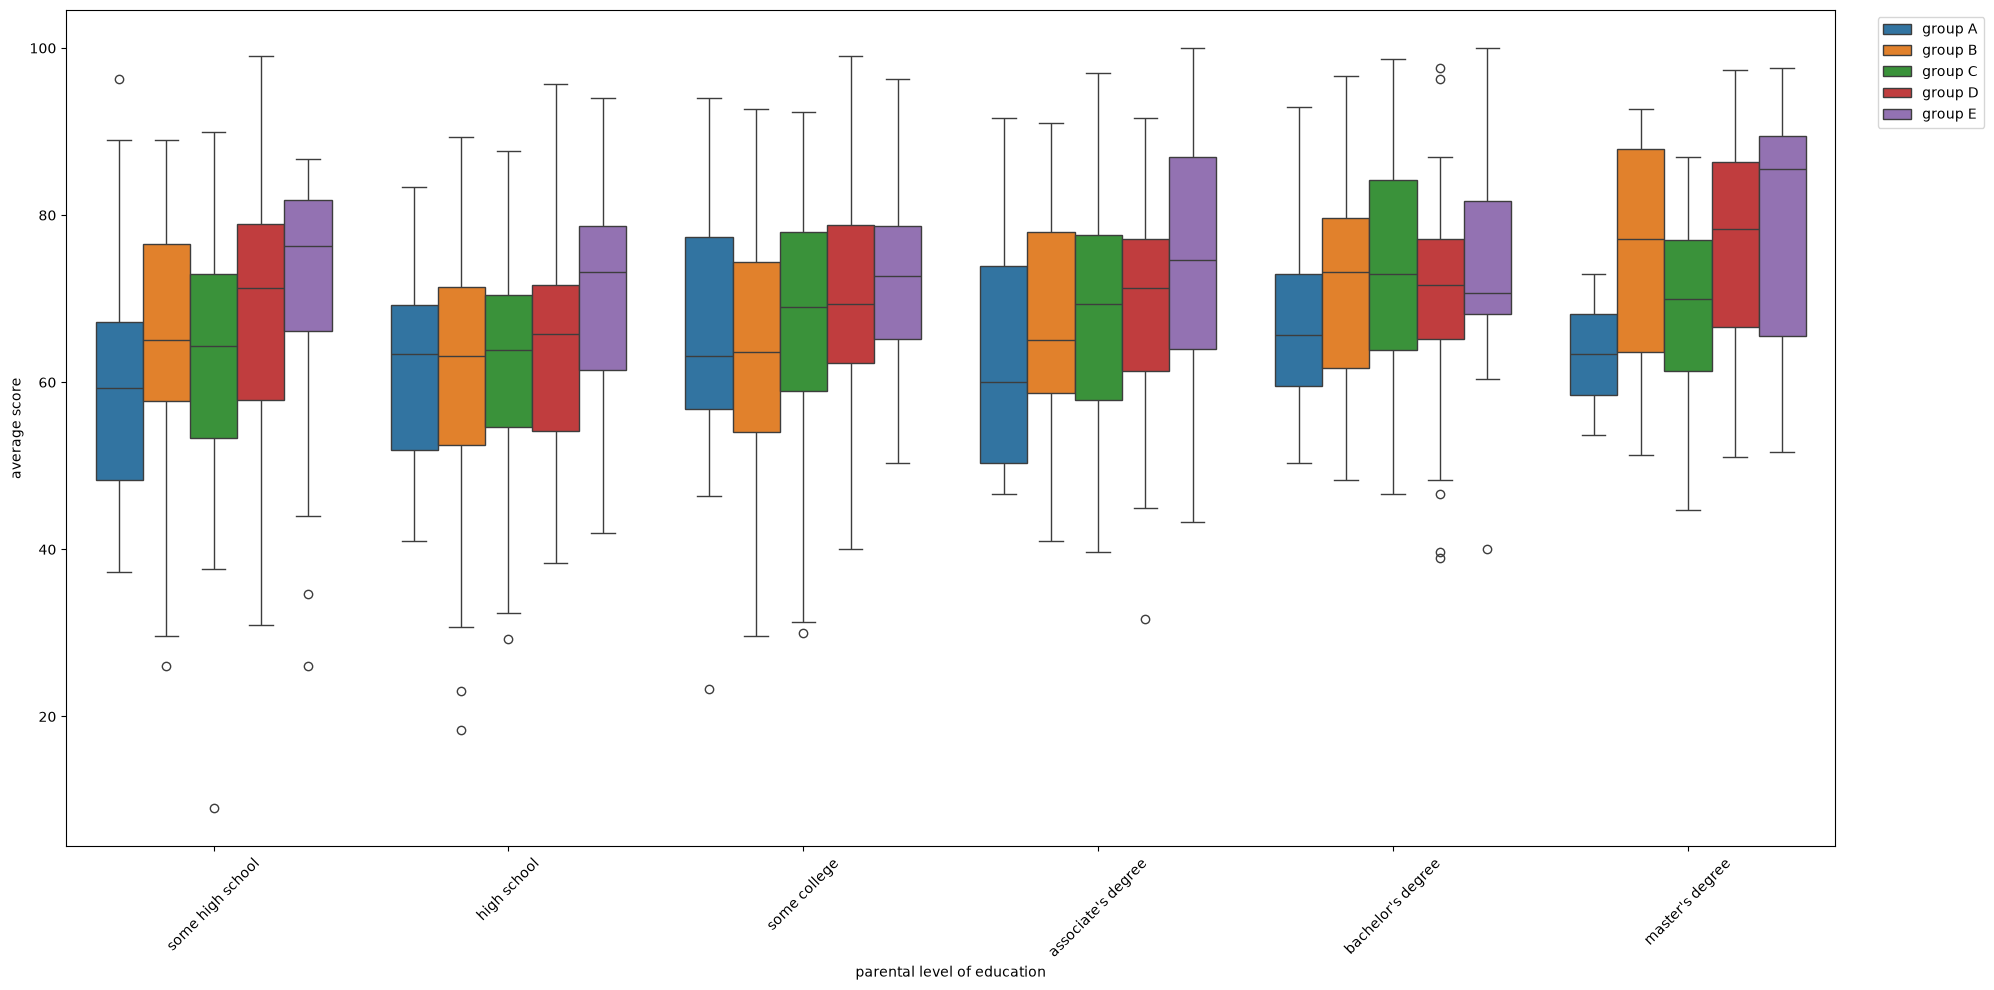

In [18]:
sns.boxplot(data = df2, x = 'parental level of education', y = 'average score', hue = 'race/ethnicity',order = ['some high school', 'high school', 'some college', 'associate\'s degree', 'bachelor\'s degree', 'master\'s degree'], hue_order = ['group A', 'group B', 'group C', 'group D', 'group E'])
plt.xticks(rotation = 45)
plt.legend(bbox_to_anchor = (1.02, 1), loc = 'upper left')
plt.tight_layout()

## 5. Identifying Correlation
Examining the correlation between numerical values by analyzing linear relationships between math, reading and writing scores

In [24]:
df3 = df2[['math score', 'reading score', 'writing score']].corr()
df3

,math score,reading score,writing score
math score,1.000000,0.817580,0.802642
reading score,0.817580,1.000000,0.954598
writing score,0.802642,0.954598,1.000000


<Axes: >

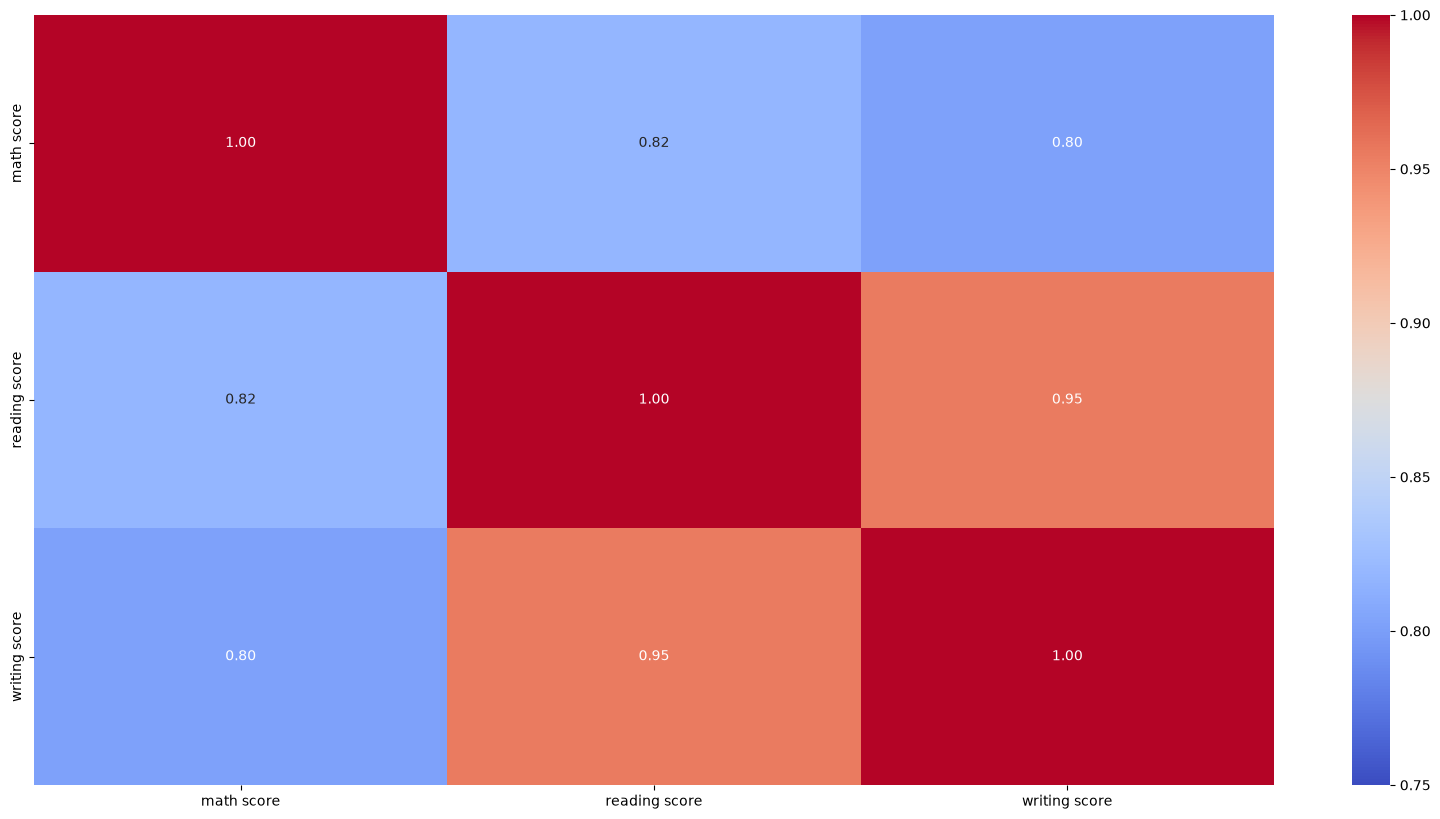

In [31]:
sns.heatmap(df3, annot = True, cmap = 'coolwarm', fmt = '.2f', vmin = 0.75, vmax = 1)